# Baseline — Stage 1: data, models, simple inference, scoring

This notebook implements the first stage of our project
([docs/proposal.md](../docs/proposal.md)): **small-object detection in aerial images**.

1. Download VisDrone2019-DET into `data/` (train / val / test-dev).
2. Simple preprocessing: convert official VisDrone annotations to YOLO format for the
   10 classes, drop ignored/don't-care regions from training targets but keep them
   for the evaluator, generate seed-42 manifests, verify class coverage and duplicates.
3. Initialize both models — **YOLO26m** and **YOLO26x** — from COCO-pretrained weights.
4. Short fine-tune on VisDrone (same shared protocol for both) to obtain stage-1 checkpoints.
5. A simple inference script that produces **baseline scores** on the validation split.
6. The shared scoring functions (`evaluate_split(...)`) that every later experiment reuses:
   mAP50–95, mAP50, recall@IoU0.5/conf0.25, tiny (<16² px) AP + recall,
   COCO small/medium/large AP + recall with per-group object counts, mean/p95 runtime.

All predictions and metrics are computed in **original-image coordinates** and
ignored regions are respected.


## 1. Setup

Fixed constants live here: seed, image size, epochs, thresholds and paths.
The thresholds follow the proposal and must not be changed after results are examined.


In [1]:
from __future__ import annotations

import hashlib
import random
import time
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path
from typing import Any

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO

SEED = 42
IMG_SIZE = 640  # training and baseline inference size
EPOCHS = 5  # stage-1 short fine-tune (full protocol later: max 50, patience 15)
BATCH = 4  # fixed for both models so only the weights differ
CONF_EVAL = 0.001  # low confidence threshold for AP (proposal)
CONF_RECALL = 0.25  # fixed recall confidence (proposal)
IOU_RECALL = 0.5  # fixed recall IoU (proposal)
IOU_NMS = 0.7  # fixed NMS IoU (proposal: fixed before looking at results)
TINY_AREA = 16**2  # tiny objects: original-image area < 16^2 px
SMALL_AREA = 32**2  # COCO small upper bound
MEDIUM_AREA = 96**2  # COCO medium upper bound
IGNORE_IOU_THR = 0.5  # drop predictions overlapping ignored regions at this IoU
MODEL_NAMES = ["yolo26m", "yolo26x"]

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
IMAGES_DIR = DATA_DIR / "images"
LABELS_DIR = DATA_DIR / "labels"
IGNORE_DIR = DATA_DIR / "ignore"
MANIFESTS_DIR = DATA_DIR / "manifests"
RUNS_DIR = ROOT / "runs" / "baseline"
VISDRONE_YAML = DATA_DIR / "visdrone.yaml"

CLASSES = [
    "pedestrian",
    "people",
    "bicycle",
    "car",
    "van",
    "truck",
    "tricycle",
    "awning-tricycle",
    "bus",
    "motor",
]
SPLITS = {
    "train": "VisDrone2019-DET-train",
    "val": "VisDrone2019-DET-val",
    "test": "VisDrone2019-DET-test-dev",
}
# Official VisDrone labels: 0 = ignored regions, 1..10 = the ten detection
# classes (mapped to YOLO ids 0..9), 11 = don't-care regions.
ASSETS_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0"

for _dir in (RAW_DIR, IMAGES_DIR, LABELS_DIR, IGNORE_DIR, MANIFESTS_DIR, RUNS_DIR):
    _dir.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device={DEVICE}")
print(f"torch={torch.__version__}")
if DEVICE == "cuda":
    print(f"gpu={torch.cuda.get_device_name(0)}")

device=cuda
torch=2.14.1+cu130
gpu=NVIDIA GeForce RTX 4060 Laptop GPU


## 2. Download the data

We pull the three official VisDrone2019-DET zips (train 1.44 GB, val 0.07 GB,
test-dev 0.28 GB) from the Ultralytics asset mirror and extract them under
`data/raw/`. Raw folders are kept for the evaluator (ignored regions).


In [2]:
def download_visdrone() -> None:
    """Download official VisDrone2019-DET zips and extract them under data/raw/."""
    for split, folder in SPLITS.items():
        target = RAW_DIR / folder
        if (target / "images").is_dir() and (target / "annotations").is_dir():
            print(f"[{split}] already extracted at {target}")
            continue
        zpath = RAW_DIR / f"{folder}.zip"
        if not zpath.exists():
            url = f"{ASSETS_URL}/{folder}.zip"
            print(f"[{split}] downloading {url}")
            urllib.request.urlretrieve(url, zpath)
        with zipfile.ZipFile(zpath) as zf:
            zf.extractall(RAW_DIR)
        print(f"[{split}] extracted {zpath.name}")


download_visdrone()

[train] already extracted at /home/danil/Documents/CV/small-object-detection/data/raw/VisDrone2019-DET-train
[val] already extracted at /home/danil/Documents/CV/small-object-detection/data/raw/VisDrone2019-DET-val
[test] already extracted at /home/danil/Documents/CV/small-object-detection/data/raw/VisDrone2019-DET-test-dev


## 3. Simple preprocessing

Convert each split once to YOLO format (`class xc yc w h`, normalized):

* official classes **1–10 → YOLO ids 0–9** in the `CLASSES` order;
* classes **0 (ignored regions)** and **11 (don't care)** are dropped from training
  targets and stored as absolute-pixel xyxy boxes in `data/ignore/<split>/` so the
  shared evaluator can respect them;
* images stay at native resolution (symlinked into `data/images/<split>/`), never resampled;
* seed-42 manifests are written to `data/manifests/<split>.csv`.


In [3]:
def convert_visdrone_split(folder: str, split: str) -> pd.DataFrame:
    """Convert one VisDrone split to YOLO labels + ignored-region files."""
    src = RAW_DIR / folder
    images_out = IMAGES_DIR / split
    labels_out = LABELS_DIR / split
    ignore_out = IGNORE_DIR / split
    for out in (images_out, labels_out, ignore_out):
        out.mkdir(parents=True, exist_ok=True)

    rows: list[dict[str, Any]] = []
    for ann_path in sorted((src / "annotations").glob("*.txt")):
        stem = ann_path.stem
        image_path = next(
            (
                src / "images" / f"{stem}{ext}"
                for ext in (".jpg", ".jpeg", ".png")
                if (src / "images" / f"{stem}{ext}").exists()
            ),
            None,
        )
        if image_path is None:
            continue
        with Image.open(image_path) as img:
            width, height = img.size

        yolo_lines: list[str] = []
        ignore_lines: list[str] = []
        for line in ann_path.read_text().strip().splitlines():
            parts = [p for p in line.strip().split(",") if p]
            if len(parts) < 8:
                continue
            x, y, bw, bh = (float(v) for v in parts[:4])
            raw_cls = int(parts[5])
            if raw_cls in (0, 11):  # ignored / don't-care regions
                ignore_lines.append(f"{x:.2f} {y:.2f} {x + bw:.2f} {y + bh:.2f} {raw_cls}")
                continue
            if not 1 <= raw_cls <= 10 or bw <= 1 or bh <= 1:
                continue
            xc, yc = x + bw / 2.0, y + bh / 2.0
            yolo_lines.append(
                f"{raw_cls - 1} {xc / width:.6f} {yc / height:.6f} {bw / width:.6f} {bh / height:.6f}"
            )

        link = images_out / image_path.name
        if not link.exists():
            link.symlink_to(image_path.resolve())
        (labels_out / f"{stem}.txt").write_text(
            "\n".join(yolo_lines) + ("\n" if yolo_lines else "")
        )
        (ignore_out / f"{stem}.txt").write_text(
            "\n".join(ignore_lines) + ("\n" if ignore_lines else "")
        )
        rows.append(
            {
                "image": image_path.name,
                "width": width,
                "height": height,
                "n_boxes": len(yolo_lines),
                "n_ignored": len(ignore_lines),
            }
        )
    return pd.DataFrame(rows).sort_values("image").reset_index(drop=True)


manifests = {split: convert_visdrone_split(folder, split) for split, folder in SPLITS.items()}

### Shared dataset YAML + seed-42 manifests + sanity checks


In [4]:
def write_visdrone_yaml() -> None:
    """Write the single dataset config reused by every training run."""
    config = {
        "path": str(DATA_DIR),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": dict(enumerate(CLASSES)),
    }
    VISDRONE_YAML.write_text(yaml.safe_dump(config, sort_keys=False))


write_visdrone_yaml()
print(VISDRONE_YAML.read_text())

path: /home/danil/Documents/CV/small-object-detection/data
train: images/train
val: images/val
test: images/test
names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor



In [5]:
def check_dataset() -> None:
    """Write manifests; verify class coverage and duplicate images."""
    for split, df in manifests.items():
        out = MANIFESTS_DIR / f"{split}.csv"
        df.to_csv(out, index=False)
        print(
            f"[{split}] {len(df)} images, {int(df['n_boxes'].sum())} boxes, "
            f"{int(df['n_ignored'].sum())} ignored regions -> {out}"
        )

    counter: Counter[int] = Counter()
    for split in ("train", "val"):
        for label_file in (LABELS_DIR / split).glob("*.txt"):
            for line in label_file.read_text().splitlines():
                if line.strip():
                    counter[int(line.split()[0])] += 1
    coverage = pd.DataFrame(
        {
            "class_id": range(len(CLASSES)),
            "class": CLASSES,
            "boxes(train+val)": [counter[i] for i in range(len(CLASSES))],
        }
    )
    display(coverage)
    assert (coverage["boxes(train+val)"] > 0).all(), "some VisDrone class is missing"

    hashes: dict[str, list[str]] = {}
    for split in SPLITS:
        for img_path in sorted((IMAGES_DIR / split).glob("*.jpg")):
            digest = hashlib.md5(img_path.read_bytes()).hexdigest()
            hashes.setdefault(digest, []).append(f"{split}/{img_path.name}")
    duplicates = {k: v for k, v in hashes.items() if len(v) > 1}
    print(f"duplicate image groups (identical bytes): {len(duplicates)}")
    for group in list(duplicates.values())[:10]:
        print("  ", group)


check_dataset()

[train] 6471 images, 343197 boxes, 10345 ignored regions -> /home/danil/Documents/CV/small-object-detection/data/manifests/train.csv
[val] 548 images, 38759 boxes, 1410 ignored regions -> /home/danil/Documents/CV/small-object-detection/data/manifests/val.csv
[test] 1610 images, 75101 boxes, 2445 ignored regions -> /home/danil/Documents/CV/small-object-detection/data/manifests/test.csv


,class_id,class,boxes(train+val)
0,0,pedestrian,88181
1,1,people,32181
2,2,bicycle,11766
3,3,car,158928
4,4,van,26931
5,5,truck,13625
6,6,tricycle,5857
7,7,awning-tricycle,3778
8,8,bus,6177
9,9,motor,34532


duplicate image groups (identical bytes): 3
   ['train/0000239_06450_d_0000017.jpg', 'train/0000239_06950_d_0000018.jpg']
   ['train/9999950_00000_d_0000079.jpg', 'train/9999950_00000_d_10000080.jpg']
   ['val/0000022_00000_d_0000004.jpg', 'val/0000023_00000_d_0000008.jpg']


### Visual sanity check — converted boxes (green) and ignored regions (red)


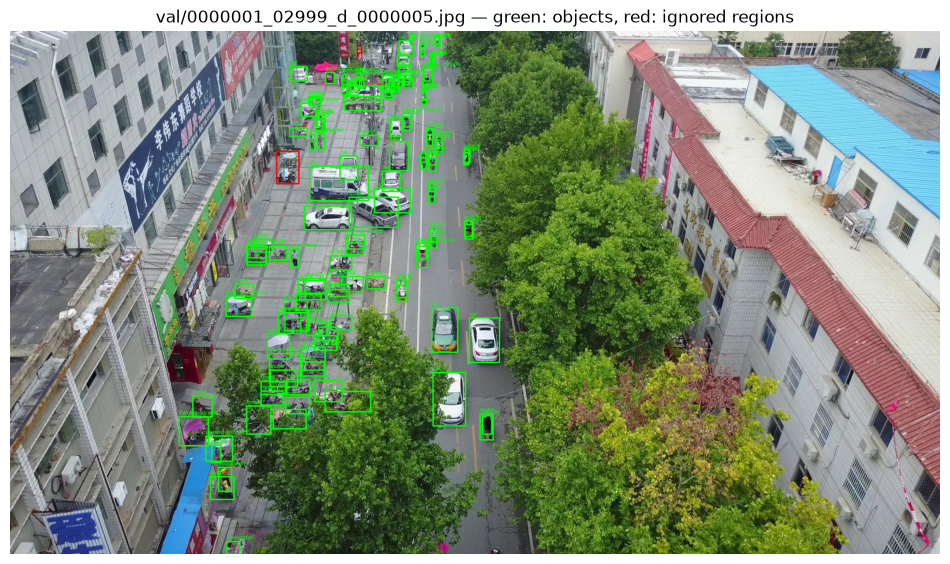

In [6]:
def show_sample(split: str = "val", index: int = 0) -> None:
    """Overlay converted YOLO boxes and ignored regions on one image."""
    row = manifests[split].iloc[index]
    image_path = IMAGES_DIR / split / row["image"]
    img = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    height, width = img.shape[:2]
    label_path = LABELS_DIR / split / f"{Path(row['image']).stem}.txt"
    for line in label_path.read_text().splitlines():
        cls_id, xc, yc, bw, bh = (float(v) for v in line.split())
        x1, y1 = int((xc - bw / 2) * width), int((yc - bh / 2) * height)
        x2, y2 = int((xc + bw / 2) * width), int((yc + bh / 2) * height)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(
            img,
            CLASSES[int(cls_id)],
            (x1, max(12, y1 - 4)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            (0, 255, 0),
            1,
        )
    ignore_path = IGNORE_DIR / split / f"{Path(row['image']).stem}.txt"
    for line in ignore_path.read_text().splitlines():
        x1, y1, x2, y2, _raw_cls = (float(v) for v in line.split())
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 2)
    plt.figure(figsize=(12, 9))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{split}/{row['image']} — green: objects, red: ignored regions")
    plt.show()


show_sample()

## 4. Initialize both models

YOLO26m (medium) and YOLO26x (largest released YOLO26 detection size), both from
COCO-pretrained weights. The detection head will be re-initialized for the 10
VisDrone classes at training time; everything else starts from COCO.


In [7]:
def init_models() -> dict[str, YOLO]:
    """Initialize both detectors from COCO-pretrained YOLO26 weights."""
    models: dict[str, YOLO] = {}
    for name in MODEL_NAMES:
        model = YOLO(f"{name}.pt")
        n_params = sum(p.numel() for p in model.model.parameters())
        print(f"{name}: {n_params / 1e6:.1f}M params, {len(model.names)} COCO classes")
        models[name] = model
    return models


base_models = init_models()

yolo26m: 21.9M params, 80 COCO classes
yolo26x: 59.0M params, 80 COCO classes


## 5. Short fine-tune (stage-1 baseline checkpoints)

Identical shared protocol for both models — only model size and pretrained
weights differ: `imgsz=640`, Ultralytics default augmentation, cosine LR,
seed 42, fixed batch. This is a deliberately short stage-1 run; the full
proposal protocol (max 50 epochs, `patience=15` on val mAP50–95) comes later.


In [8]:
def fine_tune(model_name: str) -> Path:
    """Short VisDrone fine-tune with the shared protocol; returns best checkpoint."""
    model = YOLO(f"{model_name}.pt")
    results = model.train(
        data=str(VISDRONE_YAML),
        imgsz=IMG_SIZE,
        epochs=EPOCHS,
        batch=BATCH,
        seed=SEED,
        device=DEVICE,
        cos_lr=True,
        patience=0,  # early stopping is irrelevant for a short stage-1 run
        close_mosaic=1,  # final epoch on clean geometry
        project=str(RUNS_DIR),
        name=f"{model_name}_s{IMG_SIZE}",
        exist_ok=True,
        verbose=True,
    )
    best = Path(results.save_dir) / "weights" / "best.pt"
    print(f"{model_name}: best checkpoint -> {best}")
    return best


checkpoints = {name: fine_tune(name) for name in MODEL_NAMES}

Ultralytics 8.4.175 🚀 Python-3.12.13 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 7808MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=1, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/home/danil/Documents/CV/small-object-detection/data/visdrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26m_s640, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=0, pers

Overriding model.yaml nc=80 with nc=10



                   from  n    params  module                                       arguments                     


  0                  -1  1      1856  ultralytics.nn.modules.conv.Conv             [3, 64, 3, 2]                 


...

                   bus        131        251      0.773      0.514      0.593      0.425


                 motor        485       4886      0.559      0.494      0.495      0.217


Speed: 0.1ms preprocess, 9.1ms inference, 0.0ms loss, 2.8ms postprocess per image


Results saved to /home/danil/Documents/CV/small-object-detection/runs/baseline/yolo26x_s640


yolo26x: best checkpoint -> /home/danil/Documents/CV/small-object-detection/runs/baseline/yolo26x_s640/weights/best.pt


## 6. Shared scoring functions

These functions are the single evaluator reused by **all** experiments in this
project (640 baseline, 1280 full-image, tiling, overlap sweep). The entry point is

```python
evaluate_split(labels, images, model, imgsz=..., conf=...)
```

i.e. it accepts the ground-truth labels, the original-resolution images and the
model, and returns every metric required by the proposal:

| metric | definition |
|---|---|
| `map50_95`, `map50` | pycocotools COCOeval, low conf threshold 0.001 |
| `recall50_25` | recall at IoU=0.5 and confidence=0.25 |
| `ap_tiny`, `recall_tiny` | objects with original-image area < 16² px |
| `ap_small/medium/large`, `recall_*`, `n_*` | COCO size groups + object counts |
| `runtime_mean_ms`, `runtime_p95_ms` | batch size 1, warm-up, CUDA sync |

All boxes are evaluated in **original-image coordinates**; predictions that
overlap ignored regions (VisDrone classes 0 and 11) at IoU ≥ 0.5 are dropped.


### 6.1 Paths, labels, ignored regions


In [9]:
def load_split_paths(split: str) -> tuple[list[Path], list[Path]]:
    """Aligned (images, labels) lists for a split."""
    df = manifests[split]
    images = [IMAGES_DIR / split / name for name in df["image"]]
    labels = [LABELS_DIR / split / f"{Path(name).stem}.txt" for name in df["image"]]
    return images, labels


def read_yolo_labels(label_path: Path) -> np.ndarray:
    """Return (N, 5) [class, xc, yc, w, h] normalized; shape (0, 5) when empty."""
    rows = []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) == 5:
                rows.append([float(v) for v in parts])
    return np.asarray(rows, dtype=np.float64).reshape(-1, 5)


def yolo_to_xyxy(labels: np.ndarray, width: int, height: int) -> tuple[np.ndarray, np.ndarray]:
    """Normalized YOLO boxes -> (boxes_xyxy, classes) in original-image pixels."""
    if len(labels) == 0:
        return np.zeros((0, 4), dtype=np.float64), np.zeros((0,), dtype=np.int64)
    cls = labels[:, 0].astype(np.int64)
    xc, yc, w, h = labels[:, 1], labels[:, 2], labels[:, 3], labels[:, 4]
    boxes = np.stack(
        [(xc - w / 2) * width, (yc - h / 2) * height, (xc + w / 2) * width, (yc + h / 2) * height],
        axis=1,
    ).astype(np.float64)
    return boxes, cls


def read_ignore_boxes(image_path: Path) -> np.ndarray:
    """(M, 4) absolute xyxy ignored regions for one image (empty when none)."""
    path = IGNORE_DIR / image_path.parent.name / f"{image_path.stem}.txt"
    rows = []
    if path.exists():
        for line in path.read_text().splitlines():
            parts = line.split()
            if len(parts) == 5:
                rows.append([float(v) for v in parts[:4]])
    return np.asarray(rows, dtype=np.float64).reshape(-1, 4)

### 6.2 Inference + timing


In [10]:
def _boxes_to_numpy(result: Any) -> np.ndarray:
    """Ultralytics result -> (N, 6) [x1, y1, x2, y2, conf, cls] in original coords."""
    if result.boxes is None or len(result.boxes) == 0:
        return np.zeros((0, 6), dtype=np.float64)
    boxes = result.boxes
    xyxy = boxes.xyxy.cpu().numpy().astype(np.float64)
    confs = boxes.conf.cpu().numpy().astype(np.float64)
    cls = boxes.cls.cpu().numpy().astype(np.float64)
    return np.concatenate([xyxy, confs[:, None], cls[:, None]], axis=1)


def predict_images(
    model: YOLO,
    image_paths: list[Path],
    imgsz: int,
    conf: float = CONF_EVAL,
    batch: int = 16,
) -> dict[str, np.ndarray]:
    """Prediction pass for many images (same math as batch=1, faster)."""
    preds: dict[str, np.ndarray] = {}
    for start in range(0, len(image_paths), batch):
        chunk = image_paths[start : start + batch]
        results = model.predict(
            source=[str(p) for p in chunk],
            imgsz=imgsz,
            conf=conf,
            iou=IOU_NMS,
            device=DEVICE,
            verbose=False,
        )
        for path, result in zip(chunk, results):
            preds[path.name] = _boxes_to_numpy(result)
    return preds


def benchmark_runtime(
    model: YOLO,
    image_paths: list[Path],
    imgsz: int,
    warmup: int = 10,
) -> dict[str, float]:
    """Mean/p95 ms per original image: batch 1, warm-up, CUDA synchronization."""
    all_timings: list[float] = []
    for image_path in image_paths:
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        model.predict(
            source=str(image_path),
            imgsz=imgsz,
            conf=CONF_EVAL,
            iou=IOU_NMS,
            device=DEVICE,
            verbose=False,
        )
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        all_timings.append((time.perf_counter() - start) * 1000.0)
    timings = all_timings[warmup:] or all_timings  # tiny splits: keep every timing
    array = np.asarray(timings, dtype=np.float64)
    return {
        "runtime_mean_ms": float(array.mean()),
        "runtime_p95_ms": float(np.percentile(array, 95)),
    }

### 6.3 Ignored regions + IoU utilities


In [11]:
def box_iou_matrix(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """IoU between two xyxy box sets -> (len(a), len(b))."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float64)
    top_left = np.maximum(a[:, None, :2], b[None, :, :2])
    bottom_right = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(bottom_right - top_left, 0, None)
    inter = wh[:, :, 0] * wh[:, :, 1]
    area_a = np.clip(a[:, 2] - a[:, 0], 0, None) * np.clip(a[:, 3] - a[:, 1], 0, None)
    area_b = np.clip(b[:, 2] - b[:, 0], 0, None) * np.clip(b[:, 3] - b[:, 1], 0, None)
    union = area_a[:, None] + area_b[None, :] - inter
    return np.where(union > 0, inter / union, 0.0)


def filter_ignored(
    predictions: np.ndarray,
    ignore_boxes: np.ndarray,
    iou_thr: float = IGNORE_IOU_THR,
) -> np.ndarray:
    """Respect ignored regions: drop predictions overlapping them at IoU >= thr."""
    if len(predictions) == 0 or len(ignore_boxes) == 0:
        return predictions
    ious = box_iou_matrix(predictions[:, :4], ignore_boxes)
    return predictions[ious.max(axis=1) < iou_thr]

### 6.4 mAP50–95 / mAP50 + AP per size group (pycocotools)


In [12]:
AREA_RANGES = [
    ("all", 0.0, 1e10),
    ("tiny", 0.0, float(TINY_AREA)),
    ("small", 0.0, float(SMALL_AREA)),
    ("medium", float(SMALL_AREA), float(MEDIUM_AREA)),
    ("large", float(MEDIUM_AREA), 1e10),
]


def build_coco_gt(image_paths: list[Path], label_paths: list[Path]) -> dict[str, Any]:
    """COCO gt dict from YOLO labels, in original-image coordinates."""
    images: list[dict[str, Any]] = []
    annotations: list[dict[str, Any]] = []
    ann_id = 1
    for image_id, (image_path, label_path) in enumerate(zip(image_paths, label_paths), start=1):
        with Image.open(image_path) as img:
            width, height = img.size
        images.append(
            {"id": image_id, "file_name": image_path.name, "width": width, "height": height}
        )
        boxes, classes = yolo_to_xyxy(read_yolo_labels(label_path), width, height)
        for box, cls_id in zip(boxes, classes):
            x1, y1, x2, y2 = box
            bw, bh = float(x2 - x1), float(y2 - y1)
            if bw <= 0 or bh <= 0:
                continue
            annotations.append(
                {
                    "id": ann_id,
                    "image_id": image_id,
                    "category_id": int(cls_id),
                    "bbox": [float(x1), float(y1), bw, bh],
                    "area": bw * bh,
                    "iscrowd": 0,
                }
            )
            ann_id += 1
    return {
        "images": images,
        "annotations": annotations,
        "categories": [{"id": i, "name": name} for i, name in enumerate(CLASSES)],
    }


def _load_results(coco_gt: COCO, detections: list[dict[str, Any]]) -> COCO:
    """Load detections into a COCO results object (empty-list safe)."""
    if detections:
        return coco_gt.loadRes(detections)
    coco_dt = COCO()
    coco_dt.dataset = {
        "images": list(coco_gt.dataset["images"]),
        "categories": list(coco_gt.dataset["categories"]),
        "annotations": [],
    }
    coco_dt.createIndex()
    return coco_dt


def compute_map50_95(
    gt: dict[str, Any],
    preds_by_image: dict[str, np.ndarray],
) -> dict[str, float]:
    """mAP50-95, mAP50 and AP50-95 per COCO/tiny size group via pycocotools."""
    coco_gt = COCO()
    coco_gt.dataset = gt
    coco_gt.createIndex()

    detections: list[dict[str, Any]] = []
    for image in gt["images"]:
        preds = preds_by_image.get(image["file_name"], np.zeros((0, 6)))
        for x1, y1, x2, y2, score, cls_id in preds:
            detections.append(
                {
                    "image_id": image["id"],
                    "category_id": int(cls_id),
                    "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                    "score": float(score),
                }
            )
    coco_dt = _load_results(coco_gt, detections)

    evaluator = COCOeval(coco_gt, coco_dt, iouType="bbox")
    evaluator.params.areaRng = [[lo, hi] for _, lo, hi in AREA_RANGES]
    evaluator.params.areaRngLbl = [label for label, _, _ in AREA_RANGES]
    evaluator.params.maxDets = [1, 10, 300]
    evaluator.evaluate()
    evaluator.accumulate()

    precision = evaluator.eval["precision"]  # (T, R, K, A, M)
    metrics: dict[str, float] = {}
    for area_index, (label, _, _) in enumerate(AREA_RANGES):
        values = precision[:, :, :, area_index, -1]
        values = values[values > -1]
        key = "map50_95" if label == "all" else f"ap_{label}"
        metrics[key] = float(values.mean()) if values.size else 0.0

    # mAP50 (IoU=0.50) for all objects, taken from the same precision array
    # (the summarize() path of some pycocotools builds is capped at maxDets=20)
    iou50 = 0  # precision thresholds are ordered IoU=0.50:0.05:0.95
    values = precision[iou50, :, :, 0, -1]
    values = values[values > -1]
    metrics["map50"] = float(values.mean()) if values.size else 0.0
    return metrics

### 6.5 Recall @ IoU=0.5, conf=0.25 per size group (with object counts)


In [13]:
def compute_recall(
    image_paths: list[Path],
    label_paths: list[Path],
    preds_by_image: dict[str, np.ndarray],
    conf: float = CONF_RECALL,
    iou_thr: float = IOU_RECALL,
) -> dict[str, float]:
    """Recall at fixed IoU/conf, overall and per size group, with counts."""
    total: Counter[str] = Counter()
    matched_total: Counter[str] = Counter()
    for image_path, label_path in zip(image_paths, label_paths):
        with Image.open(image_path) as img:
            width, height = img.size
        gt_boxes, _gt_classes = yolo_to_xyxy(read_yolo_labels(label_path), width, height)
        if len(gt_boxes):
            areas = (gt_boxes[:, 2] - gt_boxes[:, 0]) * (gt_boxes[:, 3] - gt_boxes[:, 1])
        else:
            areas = np.zeros(0, dtype=np.float64)
        groups = {
            "all": np.ones(len(areas), dtype=bool),
            "tiny": areas < TINY_AREA,
            "small": areas < SMALL_AREA,
            "medium": (areas >= SMALL_AREA) & (areas < MEDIUM_AREA),
            "large": areas >= MEDIUM_AREA,
        }

        preds = preds_by_image.get(image_path.name, np.zeros((0, 6)))
        preds = preds[preds[:, 4] >= conf]
        preds = preds[np.argsort(-preds[:, 4])] if len(preds) else preds

        matched = np.zeros(len(gt_boxes), dtype=bool)
        for pred in preds:
            if len(gt_boxes) == 0:
                break
            ious = box_iou_matrix(pred[None, :4], gt_boxes)[0]
            ious[matched] = -1.0
            best = int(np.argmax(ious))
            if ious[best] >= iou_thr:
                matched[best] = True

        for group, mask in groups.items():
            total[group] += int(mask.sum())
            matched_total[group] += int(matched[mask].sum())

    metrics: dict[str, float] = {}
    for group in ("all", "tiny", "small", "medium", "large"):
        metrics[f"recall_{group}" if group != "all" else "recall50_25"] = (
            matched_total[group] / total[group] if total[group] else 0.0
        )
        metrics[f"n_{group}"] = float(total[group])
    return metrics

### 6.6 The shared entry point


In [14]:
def evaluate_split(
    labels: list[Path],
    images: list[Path],
    model: YOLO,
    imgsz: int = IMG_SIZE,
    conf: float = CONF_EVAL,
    runtime_images: int | None = None,
    batch: int = 16,
) -> dict[str, float]:
    """Score one model on one split.

    Parameters
    ----------
    labels:
        ground-truth YOLO label files (one per image, same order as `images`)
    images:
        original-resolution image paths
    model:
        YOLO detector with the 10 VisDrone classes

    Returns
    -------
    dict with mAP50-95, mAP50, recall@IoU0.5/conf0.25, tiny (<16^2 px) AP and
    recall, COCO small/medium/large AP and recall with per-group object counts,
    and mean/p95 runtime per original image.
    """
    preds_by_image = predict_images(model, images, imgsz=imgsz, conf=conf, batch=batch)
    filtered = {
        image_path.name: filter_ignored(
            preds_by_image[image_path.name], read_ignore_boxes(image_path)
        )
        for image_path in images
    }
    metrics = compute_map50_95(build_coco_gt(images, labels), filtered)
    metrics.update(compute_recall(images, labels, filtered))
    n_runtime = len(images) if runtime_images is None else min(runtime_images, len(images))
    metrics.update(benchmark_runtime(model, images[:n_runtime], imgsz=imgsz))
    return metrics

## 7. Simple inference script — baseline scores

Scores every checkpoint on the validation split at `imgsz=640` (the proposal's
baseline condition) and writes `runs/baseline/baseline_scores_val_640.csv`.
Test-dev is left untouched — it is reserved for the final evaluation.


In [15]:
def run_baseline_inference(
    checkpoints: dict[str, Path],
    split: str = "val",
    imgsz: int = IMG_SIZE,
    runtime_images: int | None = None,
) -> pd.DataFrame:
    """Score every checkpoint on `split` and persist the metric table."""
    images, labels = load_split_paths(split)
    rows: list[dict[str, Any]] = []
    for name, weights in checkpoints.items():
        print(f"=== {name} @ {imgsz} on {split} ({len(images)} images) ===")
        model = YOLO(str(weights))
        metrics = evaluate_split(
            labels=labels,
            images=images,
            model=model,
            imgsz=imgsz,
            runtime_images=runtime_images,
        )
        rows.append(
            {"model": name, "weights": str(weights), "split": split, "imgsz": imgsz, **metrics}
        )
        print({k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()})
    table = pd.DataFrame(rows)
    out = RUNS_DIR / f"baseline_scores_{split}_{imgsz}.csv"
    table.to_csv(out, index=False)
    print(f"saved -> {out}")
    return table


scores = run_baseline_inference(checkpoints, split="val", imgsz=IMG_SIZE)
display(scores.T)

=== yolo26m @ 640 on val (548 images) ===


creating index...
index created!


Loading and preparing results...


DONE (t=0.36s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*


DONE (t=30.15s).
Accumulating evaluation results...


...

DONE (t=0.60s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*


DONE (t=27.72s).
Accumulating evaluation results...


DONE (t=0.89s).


{'map50_95': 0.2404, 'ap_tiny': 0.0719, 'ap_small': 0.141, 'ap_medium': 0.3607, 'ap_large': 0.5619, 'map50': 0.3936, 'recall50_25': 0.6079, 'n_all': 38759.0, 'recall_tiny': 0.323, 'n_tiny': 11955.0, 'recall_small': 0.4888, 'n_small': 26586.0, 'recall_medium': 0.8587, 'n_medium': 11105.0, 'recall_large': 0.9654, 'n_large': 1068.0, 'runtime_mean_ms': 22.1133, 'runtime_p95_ms': 23.086}
saved -> /home/danil/Documents/CV/small-object-detection/runs/baseline/baseline_scores_val_640.csv


,0,1
model,yolo26m,yolo26x
weights,/home/danil/Documents/CV/small-object-detectio...,/home/danil/Documents/CV/small-object-detectio...
split,val,val
imgsz,640,640
map50_95,0.212945,0.240362
ap_tiny,0.055939,0.071904
ap_small,0.116735,0.141012
ap_medium,0.324031,0.360667
ap_large,0.478077,0.561913
map50,0.353651,0.39359


## 8. Summary & next steps

* Stage-1 baseline scores above come from 5-epoch fine-tunes at `imgsz=640` —
  they validate the whole pipeline (data, conversion, training, scoring), not
  the final numbers of the study.
* The full protocol (max 50 epochs, `patience=15`) will produce the final
  checkpoints; `evaluate_split(labels, images, model, ...)` will score all six
  experiments (640 / 1280 full-image / 640×640 tiling @20% overlap) unchanged.
* Next: 1280 full-image inference and tiled inference at native resolution,
  then the YOLO26m tile-overlap sensitivity sweep (0% / 20% / 40%).
